In [1]:
import astropy.units as u
import numpy as np
from astropy.io import ascii

import naima
from naima.models import ExponentialCutoffPowerLaw, InverseCompton

In [3]:

## Read data

data = ascii.read("RXJ1713_HESS_2007.ecsv")

## Model definition


def ElectronIC(pars, data):

    # Match parameters to ECPL properties, and give them the appropriate units
    amplitude = pars[0] / u.eV
    alpha = pars[1]
    e_cutoff = (10 ** pars[2]) * u.TeV

    # Initialize instances of the particle distribution and radiative model
    ECPL = ExponentialCutoffPowerLaw(amplitude, 10.0 * u.TeV, alpha, e_cutoff)
    # Compute IC on CMB and on a FIR component with values from GALPROP for the
    # position of RXJ1713
    IC = InverseCompton(
        ECPL,
        seed_photon_fields=[
            "CMB",
            ["FIR", 26.5 * u.K, 0.415 * u.eV / u.cm ** 3],
        ],
        Eemin=100 * u.GeV,
    )

    # compute flux at the energies given in data['energy'], and convert to units
    # of flux data
    model = IC.flux(data, distance=1.0 * u.kpc).to(data["flux"].unit)

    # Save this realization of the particle distribution function
    elec_energy = np.logspace(11, 15, 100) * u.eV
    nelec = ECPL(elec_energy)

    # Compute and save total energy in electrons above 1 TeV
    We = IC.compute_We(Eemin=1 * u.TeV)

    # The first array returned will be compared to the observed spectrum for
    # fitting. All subsequent objects will be stores in the sampler metadata
    # blobs.
    return model, (elec_energy, nelec), We


## Prior definition


def lnprior(pars):
    """
    Return probability of parameter values according to prior knowledge.
    Parameter limits should be done here through uniform prior ditributions
    """

    logprob = naima.uniform_prior(pars[0], 0.0, np.inf) + naima.uniform_prior(
        pars[1], -1, 5
    )

    return logprob

In [6]:
## Set initial parameters and labels
p0 = np.array((1e30, 3.0, np.log10(30)))
labels = ["norm", "index", "log10(cutoff)"]

## Run sampler
sampler, pos = naima.run_sampler(
    data_table=data,
    p0=p0,
    labels=labels,
    model=ElectronIC,
    prior=lnprior,
    nwalkers=32,
    nburn=100,
    nrun=20,
    threads=4,
    prefit=True,
)

## Save run results to HDF5 file (can be read later with naima.read_run)
naima.save_run("RXJ1713_IC_run.hdf5", sampler)

## Diagnostic plots with labels for the metadata blobs
naima.save_diagnostic_plots(
    "RXJ1713_IC",
    sampler,
    sed=True,
    last_step=False,
    blob_labels=[
        "Spectrum",
        "Electron energy distribution",
        "$W_e (E_e>1\, \mathrm{TeV})$",
    ],
)
naima.save_results_table("RXJ1713_IC", sampler)


INFO: Finding Maximum Likelihood parameters through Nelder-Mead fitting... [naima.core]
INFO:    Initial parameters: [1.87859955e+32 3.00000000e+00 1.47712125e+00] [naima.core]
INFO:    Initial lnprob(p0): -175.747 [naima.core]
INFO:    New ML parameters : [1.38844563e+32 2.57175369e+00 1.68211459e+00] [naima.core]
INFO:    Maximum lnprob(p0): -18.019 [naima.core]
Burning in the 32 walkers with 100 steps...

Progress of the run: 0 percent (0 of 100 steps)
                           -----norm------ -----index----- -log10(cutoff)-
  Last ensemble median :    1.39e+32          2.57            1.68      
  Last ensemble std    :    5.96e+29         0.0164          0.00865    
  Last ensemble lnprob :  avg: -18.288, max: -18.016

Progress of the run: 5 percent (5 of 100 steps)
                           -----norm------ -----index----- -log10(cutoff)-
  Last ensemble median :    1.39e+32          2.57            1.68      
  Last ensemble std    :    1.97e+30         0.0321          0.0217  


Progress of the run: 20 percent (4 of 20 steps)
                           -----norm------ -----index----- -log10(cutoff)-
  Last ensemble median :    1.39e+32          2.54            1.67      
  Last ensemble std    :    9.99e+30          0.106           0.109     
  Last ensemble lnprob :  avg: -19.086, max: -17.987

Progress of the run: 25 percent (5 of 20 steps)
                           -----norm------ -----index----- -log10(cutoff)-
  Last ensemble median :    1.39e+32          2.54            1.67      
  Last ensemble std    :    1.02e+31          0.105           0.111     
  Last ensemble lnprob :  avg: -19.041, max: -17.987

Progress of the run: 30 percent (6 of 20 steps)
                           -----norm------ -----index----- -log10(cutoff)-
  Last ensemble median :    1.39e+32          2.54            1.65      
  Last ensemble std    :    1.02e+31          0.106           0.113     
  Last ensemble lnprob :  avg: -19.036, max: -18.066

Progress of the run: 35 percen

/home/santiagodp/anaconda3/lib/python3.8/site-packages/naima/analysis.py:160: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  f.clf()


INFO: Plotting Electron energy distribution... [naima.analysis]
INFO: Plotting $W_e (E_e>1\, \mathrm{TeV})$... [naima.analysis]
INFO: Saving results table in RXJ1713_IC_results.ecsv [naima.analysis]


label,median,unc_lo,unc_hi
bytes72,float64,float64,float64
norm,1.3791608093676229e+32,7.903550715410261e+30,1.4425253944124292e+31
index,2.5531917574130416,0.1248460419102857,0.11450466453245012
log10(cutoff),1.6826863223938404,0.13172667740945698,0.11480115728229023
cutoff,48.15998271674994,12.600140326808848,14.571811059331225
blob2,1.1248188205113748e+47,9.073071840295607e+45,1.2911032784291012e+46


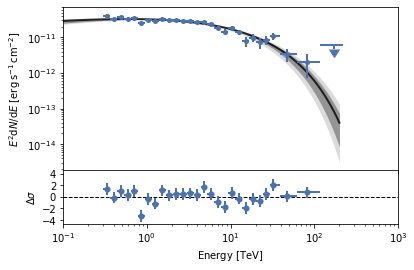

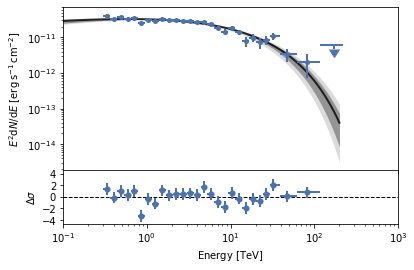

In [12]:
naima.plot_fit(sampler, e_range=[100*u.GeV, 200*u.TeV], confs=[3,1])